1) Learning rate sweep. Run vanilla gradient descent on the Rosenbrock function with learning rates [0.0001, 0.0005, 0.001, 0.005, 0.01]. Plot or print the final loss after 5000 steps for each. Find the largest learning rate that still converges.


Learning rate: 0.0001, Final loss: 2.3057176950964964
Learning rate: 0.0005, Final loss: 0.042951593583091884
Learning rate: 0.001, Final loss: 0.0037609231221175142
Learning rate: 0.005, Final loss: 0.7880389438644435
Learning rate: 0.01, Final loss: inf


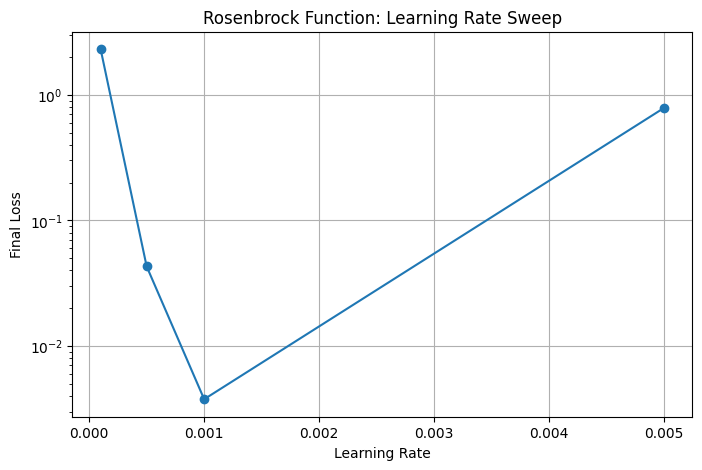

In [3]:
import matplotlib.pyplot as plt
import math

learning_rates = [0.0001, 0.0005, 0.001, 0.005, 0.01]
final_losses = []

for lr in learning_rates:
    x, y = -1.2, 1.0

    for i in range(5000):
        dx = -2 * (1 - x) - 400 * x * (y - x**2)
        dy = 200 * (y - x**2)

        x = x - lr * dx
        y = y - lr * dy

        if not math.isfinite(x) or not math.isfinite(y):
            break

        if abs(x) > 1e100 or abs(y) > 1e100:
            break

    if not math.isfinite(x) or not math.isfinite(y) or abs(x) > 1e100 or abs(y) > 1e100:
        loss = float("inf")
    else:
        loss = (1 - x)**2 + 100 * (y - x**2)**2

    final_losses.append(loss)
    print(f"Learning rate: {lr}, Final loss: {loss}")

# Plot only finite losses
plt.figure(figsize=(8, 5))

valid = [(lr, loss) for lr, loss in zip(learning_rates, final_losses)
         if math.isfinite(loss)]

if valid:
    rates, losses = zip(*valid)
    plt.plot(rates, losses, marker="o")
    
plt.xlabel("Learning Rate")
plt.ylabel("Final Loss")
plt.title("Rosenbrock Function: Learning Rate Sweep")
plt.yscale("log")
plt.grid(True)
plt.show()


2) Momentum comparison. Run SGD with momentum values [0.0, 0.5, 0.9, 0.99] on the Rosenbrock function. Track the loss at every step. Which momentum value converges fastest? Which overshoots?

Momentum: 0.0, Final loss: 0.003764244413636731
Momentum: 0.5, Final loss: 5.734225502716005e-05
Momentum: 0.9, Final loss: 8.897156270995312e-20
Momentum: 0.99, Final loss: 1.1820875358879157e-21


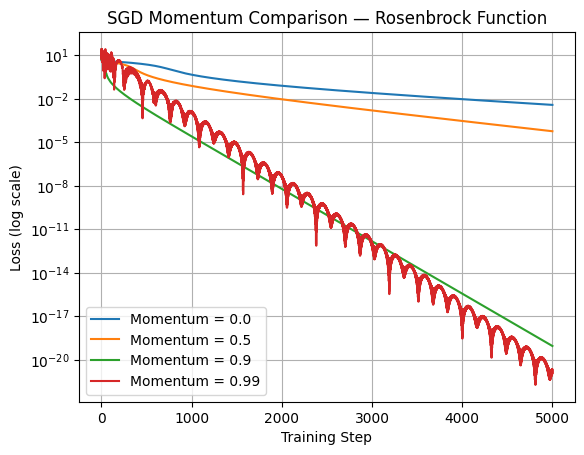

In [4]:
import matplotlib.pyplot as plt
import math

momentum_values = [0.0, 0.5, 0.9, 0.99]
learning_rate = 0.001
steps = 5000

for beta in momentum_values:
    x, y = -1.2, 1.0
    vx, vy = 0.0, 0.0
    losses = []

    for i in range(steps):
        loss = (1 - x)**2 + 100 * (y - x**2)**2

        if not math.isfinite(loss) or loss > 1e100:
            losses.extend([float("inf")] * (steps - len(losses)))
            break

        losses.append(loss)

        # Calculate gradients
        dx = -2 * (1 - x) - 400 * x * (y - x**2)
        dy = 200 * (y - x**2)

        # Update velocity
        vx = beta * vx + dx
        vy = beta * vy + dy

        # Update parameters
        x = x - learning_rate * vx
        y = y - learning_rate * vy

    print(f"Momentum: {beta}, Final loss: {losses[-1]}")

    # Plot loss at every step
    plt.plot(range(len(losses)), losses, label=f"Momentum = {beta}")

plt.yscale("log")
plt.xlabel("Training Step")
plt.ylabel("Loss (log scale)")
plt.title("SGD Momentum Comparison — Rosenbrock Function")
plt.legend()
plt.grid(True)
plt.show()

3) Saddle point escape. Define the function 
f
(
x
,
y
)
=
x
2
−
y
2
f(x,y)=x 
2
 −y 
2
  (a saddle point at the origin). Start at (0.01, 0.01). Compare how vanilla GD, SGD with momentum, and Adam behave. Which escapes the saddle point?

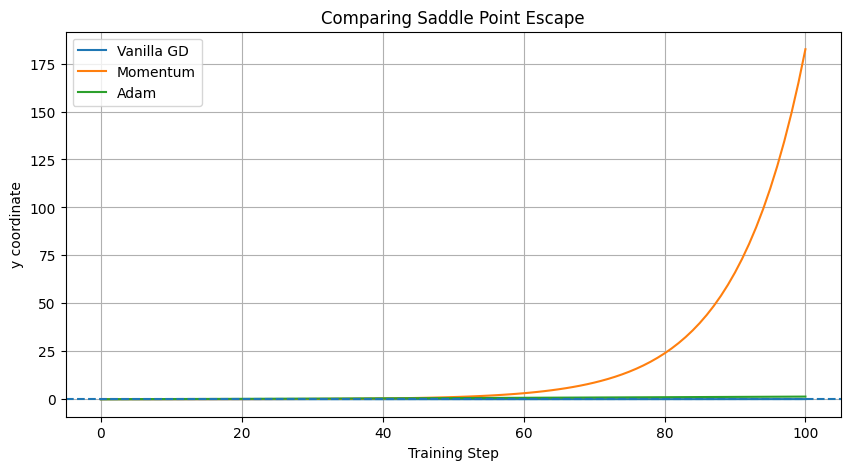

Vanilla GD: x=0.001326, y=0.072446, f(x,y)=-0.005247
Momentum: x=0.000042, y=182.477875, f(x,y)=-33298.174741
Adam: x=-0.000015, y=1.382019, f(x,y)=-1.909975


In [5]:
import numpy as np
import matplotlib.pyplot as plt

def loss(x, y):
    return x**2 - y**2

steps = 100
lr = 0.01
beta = 0.9

results = {}

x, y = 0.01, 0.01
xs, ys = [x], [y]

for _ in range(steps):
    dx = 2 * x
    dy = -2 * y

    x -= lr * dx
    y -= lr * dy

    xs.append(x)
    ys.append(y)

results["Vanilla GD"] = (xs, ys)

x, y = 0.01, 0.01
vx, vy = 0.0, 0.0
xs, ys = [x], [y]

for _ in range(steps):
    dx = 2 * x
    dy = -2 * y

    vx = beta * vx + dx
    vy = beta * vy + dy

    x -= lr * vx
    y -= lr * vy

    xs.append(x)
    ys.append(y)

results["Momentum"] = (xs, ys)

x, y = 0.01, 0.01

m_x = m_y = 0.0
v_x = v_y = 0.0

beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

xs, ys = [x], [y]

for t in range(1, steps + 1):
    dx = 2 * x
    dy = -2 * y

    m_x = beta1 * m_x + (1 - beta1) * dx
    m_y = beta1 * m_y + (1 - beta1) * dy

    v_x = beta2 * v_x + (1 - beta2) * dx**2
    v_y = beta2 * v_y + (1 - beta2) * dy**2

    m_x_hat = m_x / (1 - beta1**t)
    m_y_hat = m_y / (1 - beta1**t)

    v_x_hat = v_x / (1 - beta2**t)
    v_y_hat = v_y / (1 - beta2**t)

    x -= lr * m_x_hat / (np.sqrt(v_x_hat) + epsilon)
    y -= lr * m_y_hat / (np.sqrt(v_y_hat) + epsilon)

    xs.append(x)
    ys.append(y)

results["Adam"] = (xs, ys)

plt.figure(figsize=(10, 5))

for name, (xs, ys) in results.items():
    plt.plot(range(len(ys)), ys, label=name)

plt.axhline(0, linestyle="--")
plt.xlabel("Training Step")
plt.ylabel("y coordinate")
plt.title("Comparing Saddle Point Escape")
plt.legend()
plt.grid(True)
plt.show()

for name, (xs, ys) in results.items():
    print(
        f"{name}: x={xs[-1]:.6f}, "
        f"y={ys[-1]:.6f}, "
        f"f(x,y)={loss(xs[-1], ys[-1]):.6f}"
    )

4) Implement learning rate decay. Add an exponential decay schedule to the GradientDescent class: lr = lr_0 * 0.999^step. Compare convergence with and without decay on the Rosenbrock function.


Without decay:
Final loss: 0.00376092
Final point: (0.938726, 0.880953)

With exponential decay:
Final loss: 0.46249452
Final point: (0.320632, 0.099717)


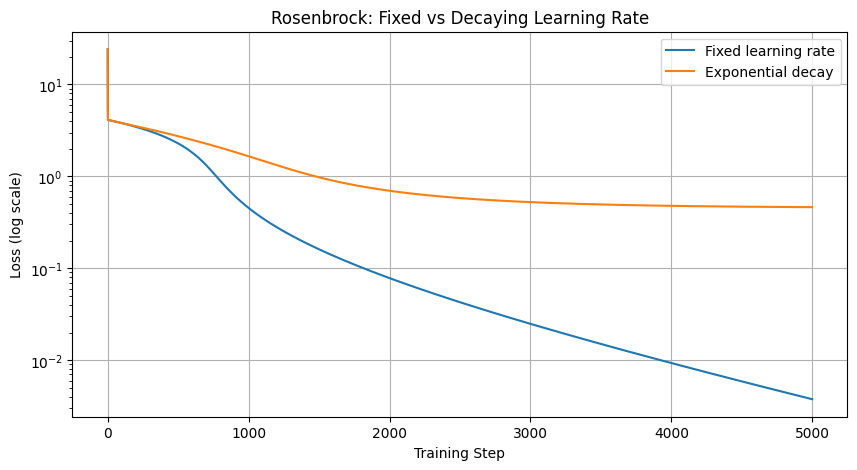

In [6]:
import numpy as np
import matplotlib.pyplot as plt

class GradientDescent:
    def __init__(self, lr_0=0.001, decay=False):
        self.lr_0 = lr_0
        self.decay = decay

    def optimize(self, steps=5000):
        x, y = -1.2, 1.0
        losses = []

        for step in range(steps):
            loss = (1 - x)**2 + 100 * (y - x**2)**2
            losses.append(loss)

            dx = -2 * (1 - x) - 400 * x * (y - x**2)
            dy = 200 * (y - x**2)

            if self.decay:
                lr = self.lr_0 * (0.999 ** step)
            else:
                lr = self.lr_0

            x -= lr * dx
            y -= lr * dy

        losses.append((1 - x)**2 + 100 * (y - x**2)**2)

        return losses, x, y


gd_fixed = GradientDescent(lr_0=0.001, decay=False)
gd_decay = GradientDescent(lr_0=0.001, decay=True)

losses_fixed, x_fixed, y_fixed = gd_fixed.optimize()
losses_decay, x_decay, y_decay = gd_decay.optimize()

print("Without decay:")
print(f"Final loss: {losses_fixed[-1]:.8f}")
print(f"Final point: ({x_fixed:.6f}, {y_fixed:.6f})")

print("\nWith exponential decay:")
print(f"Final loss: {losses_decay[-1]:.8f}")
print(f"Final point: ({x_decay:.6f}, {y_decay:.6f})")

plt.figure(figsize=(10, 5))
plt.plot(losses_fixed, label="Fixed learning rate")
plt.plot(losses_decay, label="Exponential decay")

plt.yscale("log")
plt.xlabel("Training Step")
plt.ylabel("Loss (log scale)")
plt.title("Rosenbrock: Fixed vs Decaying Learning Rate")
plt.legend()
plt.grid(True)
plt.show()